# Chapitre 14 - Exercices 14.13 à 14.17

Ce notebook traite cinq exercices consacrés aux méthodes de **réduction de dimension
non linéaires ou latentes** du chapitre 14 :

- **14.13** : courbe principale et carte auto-organisatrice (SOM) sur une hélice ;
- **14.14** : analyse factorielle et matrice de corrélation ;
- **14.15** : ACP contre analyse factorielle sur un exemple de G. Hinton ;
- **14.16** : ACP à noyau, rang et projection de nouvelles observations ;
- **14.17** : ACP à noyau vue comme un problème d'optimisation fonctionnelle.

Les fonctions réutilisables sont dans le module `esl/ch14_non_supervise_complements.py`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch14_non_supervise_complements as nsc
set_style()

## Exercice 14.13 : Courbe principale et SOM pour une hélice

**Énoncé (reformulé).** On simule $N=200$ points de $\mathbb{R}^3$ proches d'une hélice :
$$X_1 = \cos(s) + 0{,}1\,Z_1,\qquad X_2 = \sin(s) + 0{,}1\,Z_2,\qquad X_3 = s + 0{,}1\,Z_3,$$
où $s$ parcourt 200 valeurs régulièrement espacées de $[0, 2\pi]$ et $Z_1, Z_2, Z_3$ sont
des gaussiennes centrées réduites indépendantes.

(a) Ajuster une **courbe principale** et tracer les fonctions coordonnées estimées ;
les comparer à $\cos(s)$, $\sin(s)$ et $s$.

(b) Ajuster une **carte auto-organisatrice** (SOM) aux mêmes données et voir si elle
retrouve la forme hélicoïdale du nuage.

### Rappel : courbe principale (section 14.5.2 du livre)

Une courbe paramétrée $f(\lambda) = (f_1(\lambda), \dots, f_p(\lambda))$ est une **courbe
principale** de la loi de $X$ si elle est *auto-cohérente* (éq. (14.61) du livre) :
$$f(\lambda) = \mathbb{E}\big[X \,\big|\, \lambda_f(X) = \lambda\big],$$
où $\lambda_f(x)$ est le paramètre du point de la courbe le plus proche de $x$.
Autrement dit, chaque point de la courbe est la moyenne des points qui se projettent sur lui.

> **Intuition.** C'est l'analogue « courbe » de la première composante principale :
> la droite de l'ACP est la droite auto-cohérente pour une loi gaussienne.

### L'algorithme alterné (14.62)

Avec des données, on part de la première composante principale (le paramètre $\lambda_i$
est la coordonnée de $x_i$ sur cette droite), puis on alterne :

- **(a) lissage** : pour chaque coordonnée $j$, on estime $\hat f_j(\lambda) \approx
  \mathbb{E}(X_j \mid \lambda)$ en lissant les $x_{ij}$ en fonction des $\hat\lambda_i$
  (nous utilisons une régression linéaire locale à noyau gaussien) ;
- **(b) projection** : chaque $x_i$ est projeté sur la courbe $\hat f$, ce qui donne
  un nouveau $\hat\lambda_i$ égal à l'**abscisse curviligne** (longueur d'arc depuis
  l'origine de la courbe) du point le plus proche.

La somme des distances au carré $\sum_i \|x_i - \hat f(\hat\lambda_i)\|^2$ sert de critère
de suivi.

In [2]:
rng = np.random.RandomState(0)
N = 200
s = np.linspace(0, 2 * np.pi, N)
X = np.column_stack([np.cos(s), np.sin(s), s]) + 0.1 * rng.randn(N, 3)
X[:3].round(3)

array([[ 1.176,  0.04 ,  0.098],
       [ 1.224,  0.218, -0.066],
       [ 1.093,  0.048,  0.053]])

Visualisons le nuage en trois dimensions : l'hélice fait un tour complet autour de l'axe
$X_3$.

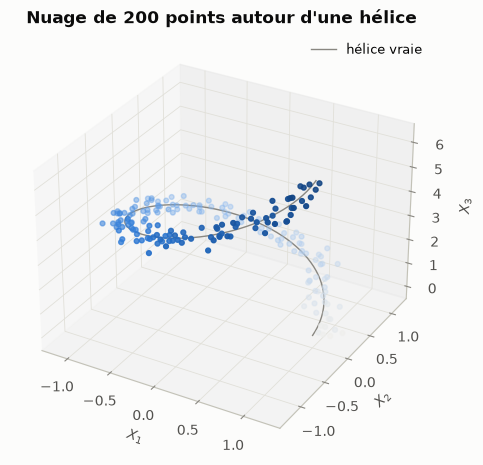

In [3]:
fig = plt.figure(figsize=(7, 5.5))
ax = fig.add_subplot(projection="3d")
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=s, cmap=SEQ, s=12)
ax.plot(np.cos(s), np.sin(s), s, color=GRAY, lw=1, label="hélice vraie")
ax.set_xlabel("$X_1$"); ax.set_ylabel("$X_2$"); ax.set_zlabel("$X_3$")
ax.set_title("Nuage de 200 points autour d'une hélice")
ax.legend()
plt.show()

### (a) Ajustement de la courbe principale

On lance 15 itérations de l'algorithme. La largeur du noyau vaut 8 % de la longueur de la
courbe : assez petite pour suivre les oscillations de $\cos$ et $\sin$, assez grande pour
lisser le bruit.

In [4]:
pc = nsc.principal_curve(X, n_iter=15, bandwidth_frac=0.08)
pc["history"].round(3)

array([5.795, 5.799, 5.803, 5.801, 5.798, 5.796, 5.795, 5.793, 5.792,
       5.791, 5.79 , 5.789, 5.789, 5.788, 5.788])

Le critère décroît légèrement puis se stabilise : l'initialisation par la première
composante principale (dirigée selon $X_3$, l'axe de l'hélice) est déjà bonne pour la
projection, et les itérations ajustent la courbe.

### Comparaison des fonctions coordonnées

La courbe est paramétrée par l'abscisse curviligne $\lambda$, qui n'est définie qu'à une
**reparamétrisation près** (origine, sens de parcours, échelle). Pour l'hélice vraie,
la vitesse est $\|(-\sin s, \cos s, 1)\| = \sqrt 2$, donc $\lambda = \sqrt2\, s$.
Comme la courbe estimée est un peu raccourcie aux extrémités (effet de bord du lisseur),
nous ramenons simplement $\lambda$ sur $[0, 2\pi]$ par une transformation affine, en
choisissant le sens de parcours qui suit $s$.

In [5]:
lam, F, grid = pc["lam"], pc["curve"], pc["grid"]
if np.corrcoef(lam, s)[0, 1] < 0:          # sens de parcours
    lam, grid = grid[-1] - lam, grid[-1] - grid
s_hat = 2 * np.pi * (lam - grid.min()) / (grid.max() - grid.min())
s_grid = 2 * np.pi * (grid - grid.min()) / (grid.max() - grid.min())
print("corrélation entre s et le paramètre estimé : %.4f" % np.corrcoef(s, s_hat)[0, 1])

corrélation entre s et le paramètre estimé : 0.9992


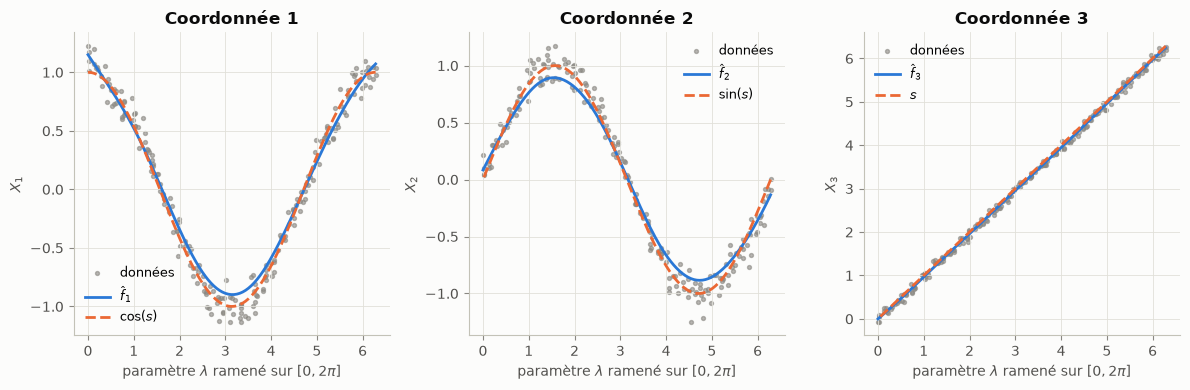

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
truth = [np.cos, np.sin, lambda u: u]
names = [r"$\cos(s)$", r"$\sin(s)$", r"$s$"]
for j, ax in enumerate(axes):
    ax.scatter(s_hat, X[:, j], s=8, color=GRAY, alpha=0.6, label="données")
    ax.plot(s_grid, F[:, j], color=BLUE, label=r"$\hat f_%d$" % (j + 1))
    ax.plot(s_grid, truth[j](s_grid), color=ORANGE, ls="--", label=names[j])
    ax.set_xlabel(r"paramètre $\lambda$ ramené sur $[0, 2\pi]$")
    ax.set_ylabel("$X_%d$" % (j + 1))
    ax.set_title("Coordonnée %d" % (j + 1))
    ax.legend()
plt.tight_layout()
plt.show()

Les trois fonctions coordonnées estimées suivent de très près $\cos(s)$, $\sin(s)$ et $s$.
On observe un léger **aplatissement aux extrémités** et aux extrema de $\cos$/$\sin$ :
c'est le biais classique d'un lisseur, qui moyenne des points situés de part et d'autre
d'un sommet.

Vue 3D de la courbe principale obtenue :

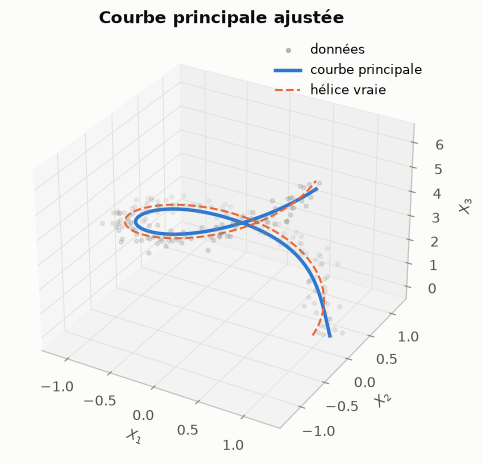

In [7]:
fig = plt.figure(figsize=(7, 5.5))
ax = fig.add_subplot(projection="3d")
ax.scatter(X[:, 0], X[:, 1], X[:, 2], color=GRAY, s=8, alpha=0.5, label="données")
ax.plot(F[:, 0], F[:, 1], F[:, 2], color=BLUE, lw=2.5, label="courbe principale")
ax.plot(np.cos(s), np.sin(s), s, color=ORANGE, ls="--", lw=1.5, label="hélice vraie")
ax.set_xlabel("$X_1$"); ax.set_ylabel("$X_2$"); ax.set_zlabel("$X_3$")
ax.set_title("Courbe principale ajustée")
ax.legend()
plt.show()

### (b) Carte auto-organisatrice

**Rappel (section 14.4).** Une SOM est un ensemble de $K$ prototypes $m_k \in \mathbb{R}^p$
indexés par des coordonnées entières $\ell_k$ sur une grille (ici une **chaîne** de 20
prototypes, $\ell_k = k$). Les observations sont traitées une à une : on cherche le
prototype $m_j$ le plus proche de $x_i$, puis tous les voisins $m_k$ de $m_j$ **sur la
grille** ($|\ell_k - \ell_j| \le r$) sont rapprochés de $x_i$ (éq. (14.46) du livre) :
$$m_k \leftarrow m_k + \alpha\,(x_i - m_k).$$
Le taux $\alpha$ décroît de 1 à 0 et le rayon $r$ de 10 à 1 au fil des itérations.

> **Intuition.** Une chaîne de prototypes est une version discrète de courbe principale :
> les prototypes voisins sur la chaîne sont tirés vers des zones voisines des données.

In [8]:
M1, coords1 = nsc.som_fit(X, (20,), n_epochs=50, random_state=0)
M1[:4].round(2)

array([[ 0.93, -0.39,  5.93],
       [ 0.82, -0.5 ,  5.77],
       [ 0.64, -0.72,  5.43],
       [ 0.37, -0.87,  5.12]])

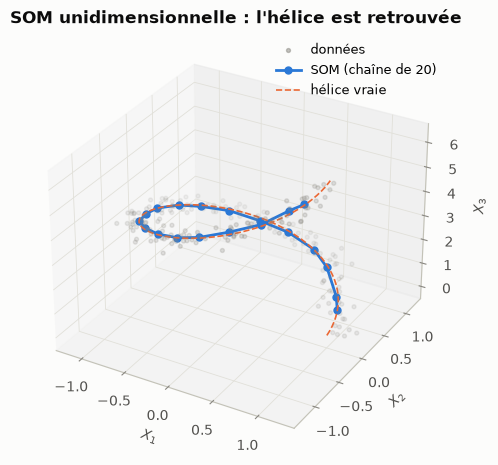

In [9]:
fig = plt.figure(figsize=(7, 5.5))
ax = fig.add_subplot(projection="3d")
ax.scatter(X[:, 0], X[:, 1], X[:, 2], color=GRAY, s=8, alpha=0.5, label="données")
ax.plot(M1[:, 0], M1[:, 1], M1[:, 2], "-o", color=BLUE, ms=5, label="SOM (chaîne de 20)")
ax.plot(np.cos(s), np.sin(s), s, color=ORANGE, ls="--", lw=1.2, label="hélice vraie")
ax.set_xlabel("$X_1$"); ax.set_ylabel("$X_2$"); ax.set_zlabel("$X_3$")
ax.set_title("SOM unidimensionnelle : l'hélice est retrouvée")
ax.legend()
plt.show()

La chaîne de prototypes s'enroule autour de l'axe $X_3$ : la forme hélicoïdale est
découverte. Pour le vérifier quantitativement, traçons les coordonnées des prototypes en
fonction de leur rang sur la chaîne.

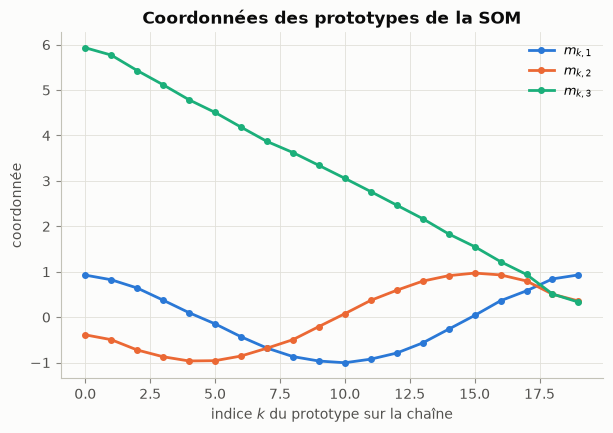

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))
k = np.arange(20)
for j in range(3):
    ax.plot(k, M1[:, j], "-o", color=COLORS[j], ms=4, label="$m_{k,%d}$" % (j + 1))
ax.set_xlabel("indice $k$ du prototype sur la chaîne")
ax.set_ylabel("coordonnée")
ax.set_title("Coordonnées des prototypes de la SOM")
ax.legend()
plt.show()

On retrouve un cosinus, un sinus (à l'orientation près) et une rampe linéaire.

**Grille bidimensionnelle.** Avec une grille $2 \times 12$ (plus proche de l'usage
classique des SOM), la nappe de prototypes forme un « ruban » enroulé autour de
l'hélice. On compare aussi l'erreur de reconstruction $\sum_i \|x_i - m_{j(i)}\|^2$ à
celle des $K$-moyennes avec le même nombre de centres, comme le suggère le livre : la
SOM est une version contrainte des $K$-moyennes, son erreur est donc plus grande, et
l'écart mesure le « coût » de la contrainte.

In [11]:
from sklearn.cluster import KMeans   # pour comparaison seulement

M2, coords2 = nsc.som_fit(X, (2, 12), n_epochs=50, random_state=0)

def reconstruction_error(X, M):
    return ((X[:, None, :] - M[None]) ** 2).sum(2).min(1).sum()

for name, M in [("SOM chaîne 20", M1), ("SOM grille 2x12", M2)]:
    km = KMeans(len(M), n_init=10, random_state=0).fit(X)
    print("%-16s erreur SOM = %6.2f   erreur K-moyennes (K=%d) = %6.2f"
          % (name, reconstruction_error(X, M), len(M), km.inertia_))

SOM chaîne 20    erreur SOM =   8.69   erreur K-moyennes (K=20) =   6.41
SOM grille 2x12  erreur SOM =  10.16   erreur K-moyennes (K=24) =   5.06


La chaîne (contrainte unidimensionnelle, adaptée à une hélice) reste assez proche des
$K$-moyennes. La grille $2\times 12$ paie davantage sa contrainte : les données n'ont
qu'une dimension intrinsèque, et la seconde dimension de la grille ne sert à rien
(les deux lignes de prototypes restent presque superposées, voir la figure suivante).

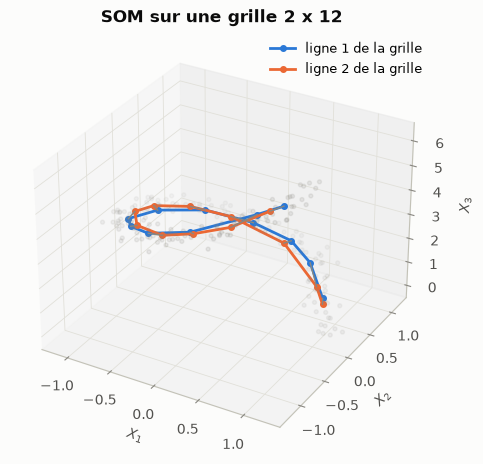

In [12]:
fig = plt.figure(figsize=(7, 5.5))
ax = fig.add_subplot(projection="3d")
ax.scatter(X[:, 0], X[:, 1], X[:, 2], color=GRAY, s=8, alpha=0.4)
G = M2.reshape(2, 12, 3)
for a in range(2):
    ax.plot(G[a, :, 0], G[a, :, 1], G[a, :, 2], "-o", color=COLORS[a], ms=4,
            label="ligne %d de la grille" % (a + 1))
for b in range(12):
    ax.plot(G[:, b, 0], G[:, b, 1], G[:, b, 2], color=GRAY, lw=1)
ax.set_xlabel("$X_1$"); ax.set_ylabel("$X_2$"); ax.set_zlabel("$X_3$")
ax.set_title("SOM sur une grille 2 x 12")
ax.legend()
plt.show()

> **À retenir.** La courbe principale estime des fonctions coordonnées lisses très
> proches de $(\cos s, \sin s, s)$, au biais de lissage près (extrema aplatis, extrémités
> raccourcies) et à une reparamétrisation près. La SOM, version discrète et contrainte des
> $K$-moyennes, retrouve aussi l'hélice, avec une erreur de reconstruction proche de celle
> des $K$-moyennes.

## Exercice 14.14 : Analyse factorielle et matrice de corrélation

**Énoncé (reformulé).** Multiplier à gauche et à droite la relation (14.81) du livre,
$$\Sigma = AA^T + D_\varepsilon,$$
par une matrice diagonale construite à partir des variances des $X_j$, et en déduire une
décomposition équivalente de la **matrice de corrélation**, au sens où l'on applique
seulement un changement d'échelle à la matrice $A$.

### Rappels

Le modèle factoriel (éq. (14.80)) s'écrit $X = AS + \varepsilon$ avec $S \in \mathbb{R}^q$
de covariance $I_q$, $A$ de taille $p\times q$ (les **saturations** ou *loadings*) et
$\varepsilon$ un bruit de composantes non corrélées entre elles et avec $S$, de variances
$\psi_j$ ; on note $D_\varepsilon = \operatorname{diag}(\psi_1,\dots,\psi_p)$.
Par bilinéarité de la covariance,
$$\Sigma = \operatorname{Cov}(X) = A\,\operatorname{Cov}(S)\,A^T + \operatorname{Cov}(\varepsilon)
= AA^T + D_\varepsilon.$$

La **matrice de corrélation** est $R = \Delta \Sigma \Delta$ avec
$\Delta = \operatorname{diag}(\sigma_1^{-1},\dots,\sigma_p^{-1})$, où
$\sigma_j^2 = \Sigma_{jj}$ : en effet $R_{jk} = \Sigma_{jk}/(\sigma_j\sigma_k)$.

> **Remarque.** Pour obtenir la matrice de corrélation, il faut multiplier par les
> **inverses des écarts-types** $\sigma_j^{-1}$ (c'est-à-dire par
> $\operatorname{diag}(\Sigma)^{-1/2}$). Multiplier par les inverses des variances
> donnerait $\operatorname{diag}(\Sigma)^{-1}\Sigma\operatorname{diag}(\Sigma)^{-1}$, qui
> se décompose de la même façon, mais n'est pas la matrice de corrélation. Nous traitons
> le cas des écarts-types ; l'argument vaut pour toute matrice diagonale inversible.

### Solution

Soit $\Delta$ diagonale inversible quelconque. On multiplie (14.81) à gauche et à droite
par $\Delta$ ; par distributivité :
$$\Delta\Sigma\Delta = \Delta A A^T \Delta + \Delta D_\varepsilon \Delta.$$
Comme $\Delta$ est symétrique, $A^T\Delta = A^T\Delta^T = (\Delta A)^T$, donc
$$\Delta\Sigma\Delta = (\Delta A)(\Delta A)^T + \Delta D_\varepsilon\Delta.$$
Enfin $\Delta D_\varepsilon \Delta = \operatorname{diag}(\psi_j/\sigma_j^2)$ est encore
**diagonale** (produit de matrices diagonales).

Avec $\Delta = \operatorname{diag}(\Sigma)^{-1/2}$, on obtient
$$\boxed{R = A^\star A^{\star T} + D^\star_\varepsilon,\qquad A^\star = \Delta A,\quad
D^\star_\varepsilon = \operatorname{diag}\!\Big(\frac{\psi_j}{\sigma_j^2}\Big).}$$
C'est encore un modèle factoriel à $q$ facteurs : la ligne $j$ de $A$ est simplement
divisée par $\sigma_j$. Les diagonales donnent
$1 = \sum_k (a^\star_{jk})^2 + \psi_j/\sigma_j^2$ : la part de variance de $X_j$ expliquée
par les facteurs (la *communauté*) plus la part spécifique (l'*unicité*).

**Conséquence.** Changer les unités des variables ($X_j \to c_j X_j$) revient à
remplacer $A$ par $\operatorname{diag}(c)A$ et $\psi_j$ par $c_j^2\psi_j$ : la structure
du modèle est inchangée. Par conséquent l'estimateur du maximum de vraisemblance est
**équivariant** par changement d'échelle : ajuster le modèle sur les données
standardisées revient à standardiser le modèle ajusté. L'analyse factorielle modélise
donc la structure de **corrélation**, contrairement à l'ACP dont les directions changent
quand on change les unités.

### Vérification numérique

Nous estimons le modèle par maximum de vraisemblance (fonction `factor_analysis_ml` :
pour des $\psi_j$ fixés les saturations optimales sont explicites, puis on optimise en
$\psi$). On compare l'ajustement sur les données brutes, ramené à l'échelle des
corrélations, à l'ajustement direct sur les données standardisées.

In [13]:
rng = np.random.RandomState(0)
N, p, q = 500, 5, 2
A_true = rng.randn(p, q)
scales = np.array([1.0, 10.0, 0.1, 3.0, 50.0])          # unités très différentes
Xf = (rng.randn(N, q) @ A_true.T + 0.7 * rng.randn(N, p)) * scales

A_raw, psi_raw, _ = nsc.factor_analysis_ml(Xf, q)
A_std, psi_std, _ = nsc.factor_analysis_ml(Xf / Xf.std(0), q)
A_star, psi_star = nsc.standardize_factor_model(A_raw, psi_raw)

# les saturations ne sont définies qu'à rotation près : on compare A A^T
print("écart max sur A*A*^T :", np.abs(A_star @ A_star.T - A_std @ A_std.T).max().round(6))
print("écart max sur les unicités :", np.abs(psi_star - psi_std).max().round(6))

écart max sur A*A*^T : 5e-06
écart max sur les unicités : 5e-06


Les deux ajustements coïncident (aux erreurs d'optimisation près). On compare maintenant
avec l'ACP : la première direction principale des données brutes est presque
entièrement portée par la variable de plus grande échelle ($X_5$), alors que sur les
données standardisées elle est très différente.

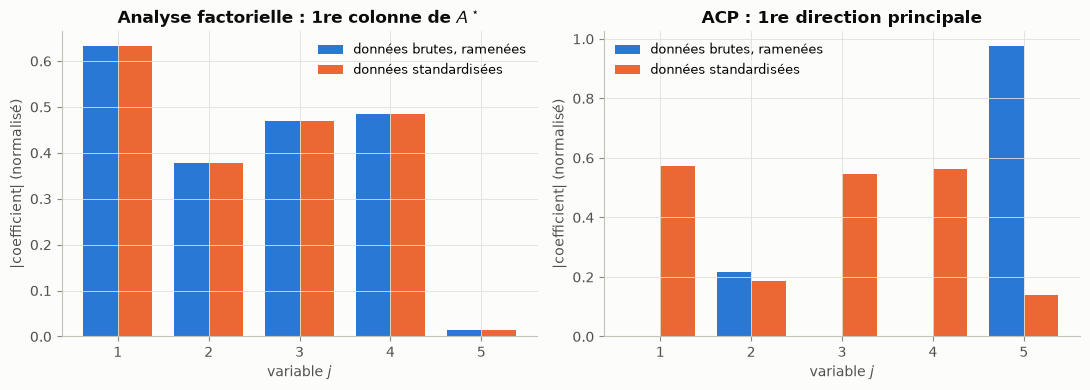

In [14]:
def first_pc(X):
    Xc = X - X.mean(0)
    return np.linalg.svd(Xc, full_matrices=False)[2][0]

v_raw, v_std = first_pc(Xf), first_pc(Xf / Xf.std(0))
v_raw_std = v_raw * Xf.std(0)
v_raw_std /= np.linalg.norm(v_raw_std)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
idx = np.arange(1, p + 1)
w = 0.38
axes[0].bar(idx - w / 2, np.abs(A_star[:, 0] / np.linalg.norm(A_star[:, 0])), w,
            color=BLUE, label="données brutes, ramenées")
axes[0].bar(idx + w / 2, np.abs(A_std[:, 0] / np.linalg.norm(A_std[:, 0])), w,
            color=ORANGE, label="données standardisées")
axes[0].set_title("Analyse factorielle : 1re colonne de $A^\\star$")
axes[1].bar(idx - w / 2, np.abs(v_raw_std), w, color=BLUE, label="données brutes, ramenées")
axes[1].bar(idx + w / 2, np.abs(v_std), w, color=ORANGE, label="données standardisées")
axes[1].set_title("ACP : 1re direction principale")
for ax in axes:
    ax.set_xlabel("variable $j$"); ax.set_ylabel("|coefficient| (normalisé)")
    ax.set_xticks(idx); ax.legend()
plt.tight_layout()
plt.show()

> **À retenir.** $\Delta\Sigma\Delta = (\Delta A)(\Delta A)^T + \Delta D_\varepsilon\Delta$ :
> standardiser les variables ne fait que redimensionner les lignes de $A$ (et les
> variances spécifiques). L'analyse factorielle est équivariante par changement
> d'échelle et décrit la structure de corrélation ; l'ACP ne l'est pas.

## Exercice 14.15 : ACP contre analyse factorielle (exemple de Hinton)

**Énoncé (reformulé).** On simule 200 observations de
$$X_1 = Z_1,\qquad X_2 = X_1 + 0{,}001\,Z_2,\qquad X_3 = 10\,Z_3 \qquad(14.117)$$
avec $Z_1,Z_2,Z_3$ normales centrées réduites indépendantes. Calculer la première
direction principale et la direction du premier facteur. Montrer que la composante
principale s'aligne sur la direction de variance maximale $X_3$, tandis que le facteur
ignore presque la composante non corrélée $X_3$ et capte la composante corrélée
$X_1 + X_2$.

### Analyse théorique

La covariance théorique est
$$\Sigma = \begin{pmatrix} 1 & 1 & 0\\ 1 & 1 + 10^{-6} & 0 \\ 0 & 0 & 100\end{pmatrix}.$$

**ACP.** $\Sigma$ est diagonale par blocs. Le bloc $2\times 2$ a pour valeurs propres
environ $2$ (vecteur $(1,1)/\sqrt2$) et $5\cdot 10^{-7}$ ; le dernier bloc vaut $100$.
La plus grande valeur propre est donc $100$, de vecteur propre $e_3$ : **la première
composante principale est $X_3$**, simplement parce que c'est la variable la plus
dispersée.

**Analyse factorielle à un facteur.** On cherche $\Sigma \approx aa^T + \operatorname{diag}(\psi)$.
Hors diagonale, il faut $a_1a_2 \approx 1$, $a_1 a_3 \approx 0$ et $a_2 a_3 \approx 0$
(les termes hors diagonale ne peuvent pas être absorbés par $\psi$). La solution est
$a \approx (1, 1, 0)$, $\psi \approx (0, 10^{-6}, 100)$ : la grande variance de $X_3$
est entièrement mise dans sa variance **spécifique** $\psi_3$, qui « ne coûte rien »,
alors que la seule corrélation du problème, entre $X_1$ et $X_2$, doit être expliquée
par le facteur.

> **Intuition.** L'ACP explique la **variance**, l'analyse factorielle explique la
> **covariance** entre variables (cf. exercice 14.14). Une variable très dispersée mais
> décorrélée des autres attire l'ACP et laisse le facteur indifférent.

In [15]:
rng = np.random.RandomState(0)
Z = rng.randn(200, 3)
X1 = Z[:, 0]
X2 = X1 + 0.001 * Z[:, 1]
X3 = 10 * Z[:, 2]
Xh = np.column_stack([X1, X2, X3])
print("écarts-types empiriques :", Xh.std(0).round(3))

écarts-types empiriques : [1.02  1.02  9.675]


Première direction principale (premier vecteur singulier droit des données centrées) :

In [16]:
v1 = first_pc(Xh)
print("1re direction principale :", (v1 * np.sign(v1[2])).round(4))

1re direction principale : [0.0096 0.0096 0.9999]


Analyse factorielle à un facteur par maximum de vraisemblance. Ici les variances
spécifiques de $X_1$ et $X_2$ tendent vers 0 (on parle de **cas de Heywood**) : c'est
précisément pour cela que nous utilisons la vraisemblance profilée plutôt que l'algorithme
EM, qui converge alors très lentement.

In [17]:
a_hat, psi_hat, ll_hat = nsc.factor_analysis_ml(Xh, 1)
a_hat = a_hat[:, 0] * np.sign(a_hat[0, 0])
print("saturations a      :", a_hat.round(4))
print("variances psi      :", psi_hat.round(7))
print("direction a/||a||  :", (a_hat / np.linalg.norm(a_hat)).round(4))

saturations a      : [1.0197 1.0197 0.8631]
variances psi      : [5.00000000e-07 5.00000000e-07 9.28535802e+01]
direction a/||a||  : [0.6068 0.6067 0.5135]


La saturation $a_3$ n'est pas nulle : elle vaut $\operatorname{Cov}(X_3, S)$, et la
corrélation empirique entre $X_3$ et $X_1$ (qui est nulle en théorie) vaut ici environ
$0{,}09$ ; multipliée par l'écart-type $\approx 9{,}7$ de $X_3$, cela donne $a_3 \approx
0{,}86$. Mais la **part de variance de $X_3$ expliquée par le facteur**,
$a_3^2/(a_3^2 + \psi_3)$, est minuscule, alors qu'elle vaut presque 1 pour $X_1$ et $X_2$.

In [18]:
communality = a_hat ** 2 / (a_hat ** 2 + psi_hat)
print("part de variance expliquée par le facteur :", communality.round(4))
print("corrélation empirique (X1, X3) : %.3f" % np.corrcoef(X1, X3)[0, 1])

part de variance expliquée par le facteur : [1.    1.    0.008]
corrélation empirique (X1, X3) : 0.089


**Direction du facteur.** Le facteur lui-même est estimé par sa prédiction linéaire
$\hat S = \mathbb E(S\mid X) = a^T\Sigma^{-1}X$. Par la formule de Woodbury,
$\Sigma^{-1}a = (aa^T + \Psi)^{-1}a = \Psi^{-1}a/(1 + a^T\Psi^{-1}a)$ : le poids de $X_j$
est proportionnel à $a_j/\psi_j$. C'est cette **direction** $b \propto \Psi^{-1}a$ qui
définit le facteur comme combinaison des variables.

In [19]:
b = a_hat / psi_hat
b /= np.linalg.norm(b)
print("direction du facteur b :", b.round(6))

direction du facteur b : [0.721014 0.692921 0.      ]


Le poids de $X_3$ est nul (à $10^{-8}$ près) : le facteur ignore complètement $X_3$. Les
poids de $X_1$ et $X_2$ sont presque égaux ; leur répartition exacte importe peu, puisque
$X_1$ et $X_2$ ne diffèrent que de $0{,}001\,Z_2$ : le facteur est essentiellement
$(X_1 + X_2)/\sqrt 2$.

**Comparaison avec l'algorithme EM** (fonction `factor_analysis_em`) : la vraisemblance
croît à chaque itération mais, après une phase rapide, l'écart au maximum ne décroît
plus que très lentement, car le maximum est au bord du domaine ($\psi_1, \psi_2 \to 0$).

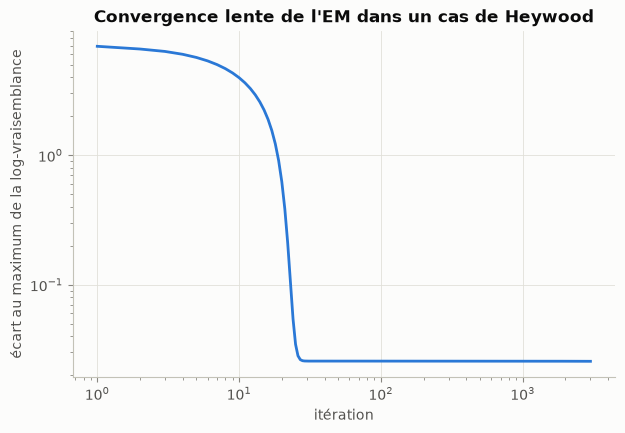

In [20]:
A_em, psi_em, ll_em = nsc.factor_analysis_em(Xh, 1, n_iter=3000)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(np.arange(1, len(ll_em) + 1), ll_hat - ll_em, color=BLUE)
ax.set_xlabel("itération")
ax.set_ylabel("écart au maximum de la log-vraisemblance")
ax.set_title("Convergence lente de l'EM dans un cas de Heywood")
plt.show()

Résumé visuel : composantes des deux directions (normalisées).

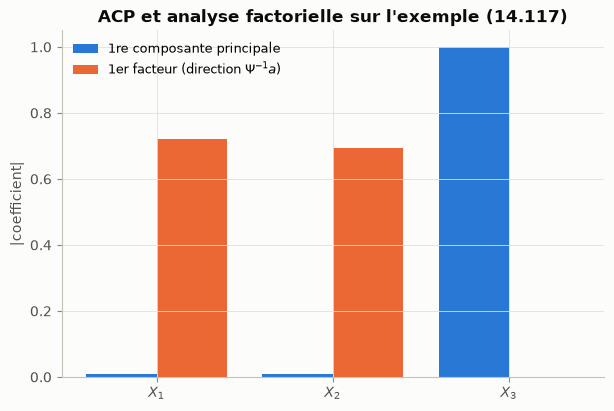

In [21]:
fig, ax = plt.subplots(figsize=(7, 4.5))
idx = np.arange(1, 4)
ax.bar(idx - 0.2, np.abs(v1), 0.4, color=BLUE, label="1re composante principale")
ax.bar(idx + 0.2, np.abs(b), 0.4, color=ORANGE,
       label="1er facteur (direction $\\Psi^{-1}a$)")
ax.set_xticks(idx); ax.set_xticklabels(["$X_1$", "$X_2$", "$X_3$"])
ax.set_ylabel("|coefficient|")
ax.set_title("ACP et analyse factorielle sur l'exemple (14.117)")
ax.legend()
plt.show()

> **À retenir.** La première composante principale est $\approx e_3$ (variance maximale),
> tandis que le premier facteur est $\approx (X_1 + X_2)/\sqrt2$ : il capte la composante
> corrélée $X_1 + X_2$ et relègue $X_3$ dans sa variance spécifique.

## Exercice 14.16 : ACP à noyau : rang et projection

**Énoncé (reformulé).** Dans la procédure d'ACP à noyau de la section 14.5.4 :

1. justifier que le nombre $M$ de composantes principales est égal au rang de la matrice
   (centrée) des noyaux, c'est-à-dire au nombre d'éléments non nuls de $D$ ;
2. montrer que la $m$-ième composante $z_m$ (colonne $m$ de $Z$) s'écrit, au centrage
   près, $z_{im} = \sum_{j=1}^N \alpha_{jm} K(x_i, x_j)$ avec $\alpha_{jm} = u_{jm}/d_m$ ;
3. montrer qu'une nouvelle observation $x_0$ a pour $m$-ième composante
   $z_{0m} = \sum_{j=1}^N \alpha_{jm} K(x_0, x_j)$.

### Rappels : ACP à partir de la matrice de Gram (éq. (14.65))

Soit $X$ la matrice $N\times p$ des données centrées et $X = UDV^T$ sa décomposition en
valeurs singulières (SVD). Les composantes principales sont $Z = XV = UD$. Or
$XX^T = UDV^TVDU^T = UD^2U^T$ : **les composantes s'obtiennent à partir de la seule
matrice des produits scalaires** $K = XX^T$ (matrice de Gram), en la diagonalisant.

Si les données ne sont pas centrées, on centre la matrice de Gram : avec
$M = \mathbf 1\mathbf 1^T/N$, la matrice $(I-M)X$ est la matrice centrée, d'où
$$\tilde K = (I - M)K(I - M) = UD^2U^T,\qquad Z = UD. \qquad (14.65)$$

**ACP à noyau.** On remplace $K_{ij} = \langle x_i, x_j\rangle$ par
$K(x_i, x_j) = \langle \phi(x_i), \phi(x_j)\rangle$ pour une transformation implicite
$\phi$ (éventuellement de dimension infinie), et l'on applique exactement la même
recette. Le noyau doit être *défini positif* : toute matrice $\{K(x_i,x_j)\}$ est
symétrique positive, ce qui garantit $\tilde K = UD^2U^T$ avec $D^2 \ge 0$.

### 1. Nombre de composantes = rang de $\tilde K$

$\tilde K$ est symétrique positive. Le théorème spectral donne une base orthonormée de
vecteurs propres $u_1,\dots,u_N$ de valeurs propres $d_1^2 \ge \dots \ge d_N^2 \ge 0$.
Les composantes $z_m = d_m u_m$ associées à $d_m = 0$ sont **identiquement nulles** :
elles ne portent aucune variance et ne sont pas de vraies composantes. Le nombre $M$ de
composantes non triviales est donc le nombre de $d_m \ne 0$.

Or, pour une matrice diagonalisable dans une base orthonormée, le rang est le nombre
de valeurs propres non nulles (l'image est engendrée par les $u_m$ tels que
$d_m \ne 0$). Donc $M = \operatorname{rang}(\tilde K)$, nombre d'éléments non nuls de $D$.

> **Remarque.** $\tilde K\mathbf 1 = (I-M)K(I-M)\mathbf 1 = 0$ puisque $(I-M)\mathbf 1 = 0$ :
> le centrage fait perdre au moins une dimension, donc $M \le N - 1$. De plus
> $\operatorname{rang}\tilde K \le \operatorname{rang} K$. Pour un noyau polynomial de degré 2
> en dimension 2, l'espace des $\phi(x)$ est de dimension 6 (monômes $1, x_1, x_2, x_1^2,
> x_1x_2, x_2^2$) et l'on attend $M \le 5$ après centrage (la constante disparaît).

### 2. Expression des composantes

Par définition $\tilde K u_m = d_m^2 u_m$. Pour $d_m > 0$ on divise par $d_m$ :
$$z_m = d_m u_m = \frac{1}{d_m}\tilde K u_m = \tilde K\,\alpha_m,\qquad
\alpha_m = \frac{u_m}{d_m}.$$
Coordonnée par coordonnée : $z_{im} = \sum_{j} \alpha_{jm}\tilde K(x_i, x_j)$, où
$\tilde K(x_i,x_j)$ est le noyau **centré**. C'est bien la formule demandée « au
centrage près ».

On peut d'ailleurs remplacer $\tilde K$ par $K$ au prix d'une constante : comme
$\mathbf 1^T u_m = 0$ (car $u_m$ est orthogonal au vecteur propre $\mathbf 1$ de valeur
propre 0), on a $\mathbf 1^T\alpha_m = 0$, et
$$\tilde K\alpha_m = (I-M)K(I-M)\alpha_m = (I-M)K\alpha_m,$$
donc $z_m$ est exactement le vecteur $K\alpha_m$ **recentré** (on lui retire sa moyenne).

### 3. Projection d'une nouvelle observation

Plaçons-nous dans l'espace des caractéristiques. Soit $\Phi$ la matrice $N\times\cdot$ de
lignes $\phi(x_i)^T$, $\bar\phi$ leur moyenne, et $\tilde\Phi = (I-M)\Phi$. La SVD
$\tilde\Phi = UDV^T$ donne les directions principales $v_m = \tilde\Phi^T u_m/d_m$
(en multipliant $\tilde\Phi = UDV^T$ à gauche par $U^T$ puis en transposant).
La $m$-ième composante d'un point $x_0$ est la coordonnée de $\phi(x_0) - \bar\phi$ sur
$v_m$ :
$$z_{0m} = (\phi(x_0) - \bar\phi)^T v_m = \sum_{j=1}^N \frac{u_{jm}}{d_m}
(\phi(x_0)-\bar\phi)^T(\phi(x_j)-\bar\phi) = \sum_j \alpha_{jm}\tilde K(x_0, x_j).$$

Le noyau centré se calcule sans connaître $\phi$ : en développant le produit scalaire,
$$\tilde K(x_0, x_j) = K(x_0,x_j) - \frac1N\sum_{l}K(x_0,x_l) - \frac1N\sum_l K(x_l,x_j)
+ \frac1{N^2}\sum_{l,l'}K(x_l,x_{l'}).$$
Et comme $\sum_j \alpha_{jm} = 0$, les termes qui ne dépendent pas de $j$ disparaissent :
$z_{0m} = \sum_j \alpha_{jm}K(x_0,x_j) + c_m$, où $c_m$ est une constante (indépendante de
$x_0$) - encore la formule demandée « au centrage près ». Pour $x_0 = x_i$ on retrouve
bien $z_{im}$.

### Vérifications numériques

**Rang.** Avec le noyau polynomial $K(x,x') = (1 + x^Tx')^2$ en dimension 2, le rang
de $\tilde K$ doit valoir 5 ; avec le noyau radial (14.67), il vaut $N-1$ (en pratique,
beaucoup de valeurs propres sont minuscules).

In [22]:
rng = np.random.RandomState(0)
Xk = rng.randn(60, 2)
K_poly = (1 + Xk @ Xk.T) ** 2
K_rbf = nsc.rbf_kernel(Xk, Xk, 2.0)
ev_poly = np.linalg.eigvalsh(nsc.center_gram(K_poly))[::-1]
ev_rbf = np.linalg.eigvalsh(nsc.center_gram(K_rbf))[::-1]
print("rang (polynomial) :", np.linalg.matrix_rank(nsc.center_gram(K_poly)))
print("rang (radial)     :", np.linalg.matrix_rank(nsc.center_gram(K_rbf), tol=1e-12))

rang (polynomial) : 5
rang (radial)     : 59


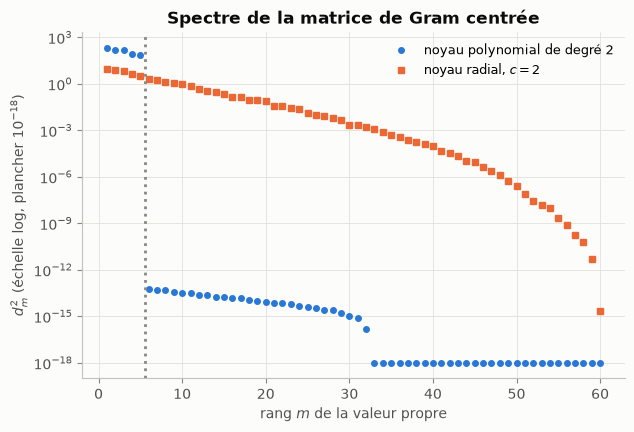

In [23]:
fig, ax = plt.subplots(figsize=(7, 4.5))
m = np.arange(1, 61)
ax.semilogy(m, np.maximum(ev_poly, 1e-18), "o", color=BLUE, ms=4,
            label="noyau polynomial de degré 2")
ax.semilogy(m, np.maximum(ev_rbf, 1e-18), "s", color=ORANGE, ms=4, label="noyau radial, $c=2$")
ax.axvline(5.5, color=GRAY, ls=":")
ax.set_xlabel("rang $m$ de la valeur propre")
ax.set_ylabel("$d_m^2$ (échelle log, plancher $10^{-18}$)")
ax.set_title("Spectre de la matrice de Gram centrée")
ax.legend()
plt.show()

Pour le noyau polynomial, les valeurs propres chutent au niveau de l'erreur machine après
la cinquième : seules 5 composantes existent.

**Composantes et projection.** On vérifie $Z = \tilde K\alpha$, que $K\alpha$ recentré
donne la même chose, et que la projection d'une nouvelle observation coïncide avec
l'implémentation de scikit-learn (utilisée seulement pour comparer, aux signes près).

In [24]:
model = nsc.kernel_pca(K_rbf)
Z, alpha = model["Z"], model["alpha"]
Ka = K_rbf @ alpha[:, :10]
print("nombre de composantes retenues :", Z.shape[1])
print("max |Z - K~ alpha|                       :",
      np.abs(Z - nsc.center_gram(K_rbf) @ alpha).max())
print("max |Z - (K alpha recentré)| (10 premières) :", np.abs(Z[:, :10] - (Ka - Ka.mean(0))).max())

nombre de composantes retenues : 55
max |Z - K~ alpha|                       : 9.02569383028914e-12
max |Z - (K alpha recentré)| (10 premières) : 9.43689570931383e-16


> **Remarque numérique.** Pour les dernières composantes, $d_m$ est minuscule et
> $\alpha_m = u_m/d_m$ amplifie les erreurs d'arrondi : l'identité
> $\mathbf 1^T\alpha_m = 0$ n'est alors plus vérifiée qu'approximativement. C'est pourquoi
> la vérification avec $K$ non centré est faite sur les 10 premières composantes.

In [25]:
from sklearn.decomposition import KernelPCA   # pour comparaison seulement

X0 = rng.randn(5, 2)
z0 = nsc.kernel_pca_transform(model, nsc.rbf_kernel(X0, Xk, 2.0))[:, :4]
z0_sk = KernelPCA(4, kernel="rbf", gamma=1 / 2.0).fit(Xk).transform(X0)
print("max | |z0| - |z0 sklearn| | :", np.abs(np.abs(z0) - np.abs(z0_sk)).max())

max | |z0| - |z0 sklearn| | : 1.4710455076283324e-15


Enfin, projeter les points d'apprentissage eux-mêmes comme de « nouvelles » observations
redonne exactement $Z$.